# 08 — Comparer les runs subset

Lit `checkpoints/<run>/history.json` (et `gold_sanity.json` s'il existe) pour
comparer des recettes entraînées sur **le même 25 % du train** (val pleine).

Les runs à comparer sont listés en dur dans `RUNS` (cellule suivante) :
commenter une ligne suffit pour retirer un checkpoint de l'analyse.

Le checkpoint se pilote sur la **val macro-AUC**. Le gold (58) et surtout
**Lateral OA / MCL** sont le signal attendu du T1 — un écart de macro-AUC
**&lt; 0,01** sur un subset de 924 études = bruit. Réf CNN : **v20b**
(val 0,839 / gold 0,885). Le ViT est un **spécialiste d'ensemble**, pas un
successeur macro du CNN.

**En cours** : ViT-e **déterministe** (seed 42), `subset_vit_dinov3_e_det_frac025`.
À comparer à **e** original (même recette, RNG non figé). j+dp local est
**fini** (best 0,816 @ ep11). Plus de pull RunPod. Overlays (tiretés) : j pod
ep8, j+dp pod ep5.

Relancer **load → graphes** pendant le train : `history.json` s'écrit à chaque epoch.


In [151]:
from __future__ import annotations

import json
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["figure.dpi"] = 100

ROOT = Path.cwd() if (Path.cwd() / "checkpoints").exists() else Path.cwd().parent
CKPT = ROOT / "checkpoints"

# Checkpoints a comparer (noms de dossiers sous checkpoints/, = run_name YAML).
# e det = train local en cours (meme recette que e, seed 42).
# Commenter une ligne pour l'exclure de l'analyse.
RUNS = [
    "subset_vit_dinov3_e_det_frac025",
    "subset_vit_dinov3_e_crop130_frac025",
    "subset_vit_j_dp01_frac025",
    "subset_v20b_crop130_frac025",
]

# (label, dossier, fichier) — histories pod, jamais ecraser le train local.
OVERLAYS = [
    ("j_dp01_runpod_ep5", "subset_vit_j_dp01_frac025", "history_runpod_ep5.json"),
    ("j_llrd08_runpod_ep8", "subset_vit_j_llrd08_frac025", "history_runpod_ep8.json"),
]

LABELS = {
    "subset_vit_j_dp01_frac025": "j+dp local",
    "subset_vit_j_llrd08_frac025": "j LLRD local",
    "subset_vit_k_llrd08_frac025": "k LLRD",
    "subset_vit_dinov3_e_det_frac025": "e det local",
    "subset_vit_dinov3_e_crop130_frac025": "e",
    "subset_v20b_crop130_frac025": "v20b CNN",
    "j_dp01_runpod_ep5": "j+dp RunPod ep5",
    "j_llrd08_runpod_ep8": "j RunPod ep8",
}

REF = "subset_v20b_crop130_frac025"  # champion CNN subset ; deltas = run − v20b

FOCUS = ["Lateral OA", "MCL", "ACL", "Medial Meniscus"]
TARGETS = [
    "ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA",
    "Lateral OA", "PF OA", "Effusion", "Synovitis", "Baker's",
    "Contusion", "Fracture",
]

print("ROOT", ROOT)
print("checkpoints", CKPT.exists())


ROOT c:\Users\sulta\Documents\RSNA-comp
checkpoints True


In [152]:
# Plus de pod RunPod : lecture locale uniquement.
# Ne pas scp — un pull casse ecraserait history.json du train 3070 (e det en cours).
print("lecture locale (pas de pull RunPod)")
for name in RUNS:
    p = CKPT / name / "history.json"
    print(f"  {LABELS.get(name, name)}: {p}  exists={p.exists()}")
for label, folder, fname in OVERLAYS:
    p = CKPT / folder / fname
    print(f"  overlay {label}: {p}  exists={p.exists()}")


lecture locale (pas de pull RunPod)
  e det local: c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_vit_dinov3_e_det_frac025\history.json  exists=True
  e: c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_vit_dinov3_e_crop130_frac025\history.json  exists=True
  j+dp local: c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_vit_j_dp01_frac025\history.json  exists=True
  v20b CNN: c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_v20b_crop130_frac025\history.json  exists=True
  overlay j_dp01_runpod_ep5: c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_vit_j_dp01_frac025\history_runpod_ep5.json  exists=True
  overlay j_llrd08_runpod_ep8: c:\Users\sulta\Documents\RSNA-comp\checkpoints\subset_vit_j_llrd08_frac025\history_runpod_ep8.json  exists=True


In [153]:
def load_run(name: str, hist_p: Path | None = None) -> dict | None:
    d = CKPT / name if hist_p is None else hist_p.parent
    hist_p = hist_p or (d / "history.json")
    if not hist_p.exists():
        print(f"  skip {name} : pas de {hist_p.name}")
        return None
    hist = pd.DataFrame(json.loads(hist_p.read_text(encoding="utf-8")))
    if hist.empty:
        print(f"  skip {name} : {hist_p.name} vide")
        return None
    gold = None
    gp = d / "gold_sanity.json"
    if gp.exists() and hist_p.name == "history.json":
        gold = json.loads(gp.read_text(encoding="utf-8"))
    uids = []
    up = d / "train_uids.txt"
    if up.exists():
        uids = [ln.strip() for ln in up.read_text(encoding="utf-8").splitlines() if ln.strip()]
    best_idx = hist["val_macro_auc"].idxmax()
    best_row = hist.loc[best_idx]
    return {
        "name": name,
        "label": LABELS.get(name, name),
        "dir": d,
        "hist": hist,
        "gold": gold,
        "uids": uids,
        "overlay": hist_p.name != "history.json",
        "done": gp.exists() and hist_p.name == "history.json",
        "best_epoch": int(best_row["epoch"]),
        "best_val": float(best_row["val_macro_auc"]),
        "best_gold": float(best_row["gold_macro_auc"]) if "gold_macro_auc" in hist.columns and pd.notna(best_row.get("gold_macro_auc")) else None,
        "last_epoch": int(hist["epoch"].max()),
        "n_epochs": int(len(hist)),
    }


def _print_rec(rec: dict, etat: str) -> None:
    gold_txt = f"gold {rec['best_gold']:.3f}" if rec["best_gold"] is not None else "gold n/a"
    n_train = len(rec["uids"]) or "?"
    print(
        f"  {rec['label']}: {etat} | best val {rec['best_val']:.4f} "
        f"@ ep {rec['best_epoch']} | {gold_txt} | n_train {n_train}"
    )


wanted = list(RUNS)
runs = []
print("runs demandes :", wanted)
for name in wanted:
    rec = load_run(name)
    if rec is None:
        continue
    runs.append(rec)
    etat = "termine" if rec["done"] else f"{rec['n_epochs']} epochs"
    _print_rec(rec, etat)

for label, folder, fname in OVERLAYS:
    rp = CKPT / folder / fname
    if not rp.exists():
        print(f"  skip overlay {label} : pas de {fname}")
        continue
    rec = load_run(label, hist_p=rp)
    if rec is None:
        continue
    rec["done"] = True
    rec["uids"] = []
    rec["overlay"] = True
    rec["label"] = LABELS.get(label, label)
    runs.append(rec)
    _print_rec(rec, "overlay")

if not runs:
    raise SystemExit("aucun history.json — lance d'abord un train subset")


def line_kw(r: dict) -> dict:
    kw = dict(marker="o", label=r["label"])
    if r.get("overlay"):
        kw["linestyle"] = "--"
        kw["alpha"] = 0.75
    return kw


runs demandes : ['subset_vit_dinov3_e_det_frac025', 'subset_vit_dinov3_e_crop130_frac025', 'subset_vit_j_dp01_frac025', 'subset_v20b_crop130_frac025']
  e det local: 2 epochs | best val 0.6693 @ ep 1 | gold 0.647 | n_train 924
  e: 7 epochs | best val 0.8075 @ ep 7 | gold 0.814 | n_train 924
  j+dp local: termine | best val 0.8165 @ ep 11 | gold 0.822 | n_train 924
  v20b CNN: 10 epochs | best val 0.8389 @ ep 10 | gold 0.885 | n_train 924
  j+dp RunPod ep5: overlay | best val 0.7839 @ ep 5 | gold 0.803 | n_train ?
  j RunPod ep8: overlay | best val 0.8206 @ ep 8 | gold 0.828 | n_train ?


## Tableau résumé

Meilleure epoch = argmax de la val macro-AUC (comme le `best.pt`).

In [154]:
rows = []
for r in runs:
    last = r["hist"].iloc[-1]
    rows.append({
        "run": r["name"],
        "label": r["label"],
        "etat": (
            "overlay" if r.get("overlay")
            else "termine" if r["done"]
            else f"{r['n_epochs']} ep"
        ),
        "n_train": len(r["uids"]) or None,
        "best_epoch": r["best_epoch"],
        "best_val_auc": r["best_val"],
        "best_gold_auc": r["best_gold"],
        "last_train_loss": float(last["loss"]),
        "last_val_loss": float(last["val_loss"]) if "val_loss" in last else None,
        "last_val_auc": float(last["val_macro_auc"]),
    })
summary = pd.DataFrame(rows).set_index("run")
display(summary.round(4))

if REF in summary.index and len(summary) > 1:
    print("\ndelta vs", REF, "(best val AUC)")
    ref_val = summary.loc[REF, "best_val_auc"]
    for name, row in summary.iterrows():
        if name == REF:
            continue
        d = row["best_val_auc"] - ref_val
        lab = LABELS.get(name, name)
        print(f"  {lab}: {d:+.4f}  {'(bruit, <0.01)' if abs(d) < 0.01 else ''}")


,label,etat,n_train,best_epoch,best_val_auc,best_gold_auc,last_train_loss,last_val_loss,last_val_auc
run,,,,,,,,,
subset_vit_dinov3_e_det_frac025,e det local,2 ep,924.0,1,0.6693,0.6466,0.5124,0.4916,0.6614
subset_vit_dinov3_e_crop130_frac025,e,7 ep,924.0,7,0.8075,0.8144,0.3777,0.4332,0.8075
subset_vit_j_dp01_frac025,j+dp local,termine,924.0,11,0.8165,0.8216,0.2851,0.4542,0.8160
subset_v20b_crop130_frac025,v20b CNN,10 ep,924.0,10,0.8389,0.8853,0.3359,0.3844,0.8389
j_dp01_runpod_ep5,j+dp RunPod ep5,overlay,NaN,5,0.7839,0.8034,0.4481,0.4638,0.7839
j_llrd08_runpod_ep8,j RunPod ep8,overlay,NaN,8,0.8206,0.8280,0.3278,0.4235,0.8206



delta vs subset_v20b_crop130_frac025 (best val AUC)
  e det local: -0.1696  
  e: -0.0314  
  j+dp local: -0.0224  
  j+dp RunPod ep5: -0.0550  
  j RunPod ep8: -0.0183  


## Courbes (tous les runs superposés)

courbes e det local: epochs [1, 2]
courbes e: epochs [1, 2, 3, 4, 5, 6, 7]
courbes j+dp local: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]
courbes v20b CNN: epochs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
courbes j+dp RunPod ep5: epochs [1, 2, 3, 4, 5]
courbes j RunPod ep8: epochs [1, 2, 3, 4, 5, 6, 7, 8]


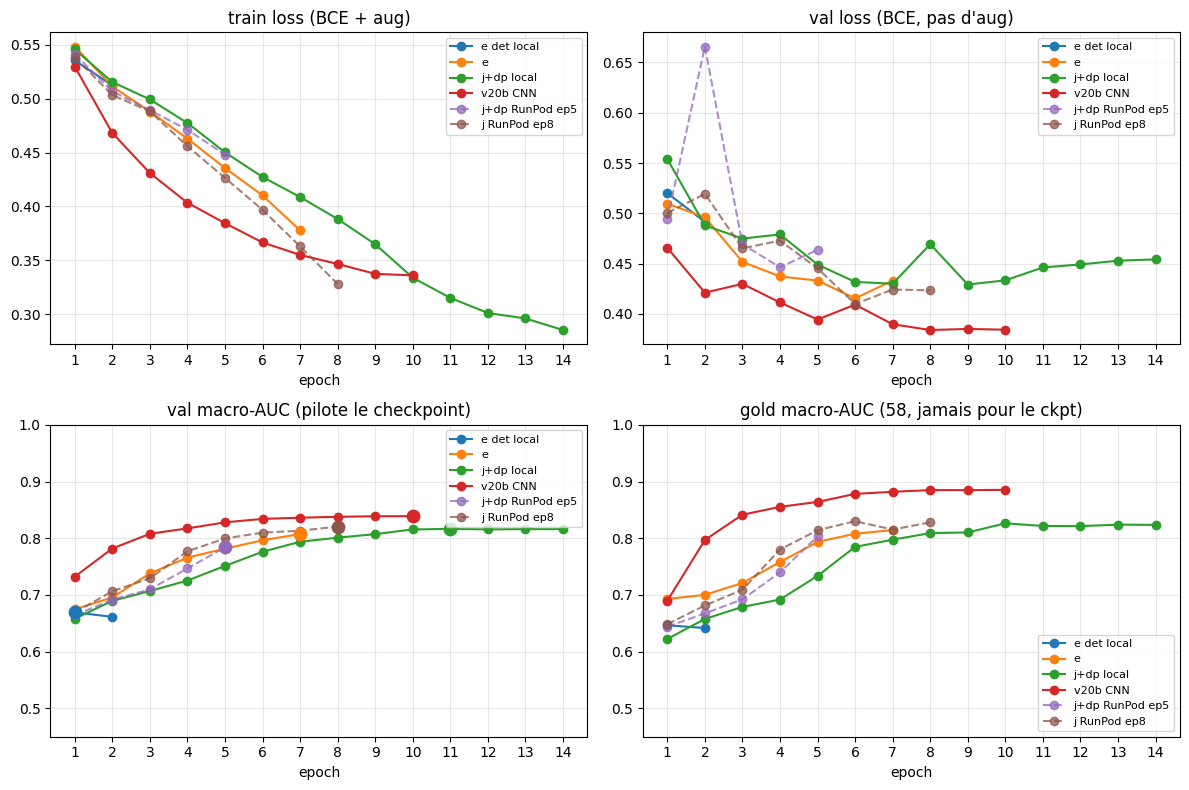

In [155]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for r in runs:
    h = r["hist"].sort_values("epoch")
    kw = line_kw(r)
    print(f"courbes {r['label']}: epochs {list(map(int, h.epoch))}")
    axes[0, 0].plot(h.epoch, h.loss, **kw)
    if "val_loss" in h.columns:
        axes[0, 1].plot(h.epoch, h.val_loss, **kw)
    axes[1, 0].plot(h.epoch, h.val_macro_auc, **kw)
    if "gold_macro_auc" in h.columns:
        axes[1, 1].plot(h.epoch, h.gold_macro_auc, **kw)
    axes[1, 0].scatter([r["best_epoch"]], [r["best_val"]], s=80, zorder=5)

emax = max(int(r["hist"]["epoch"].max()) for r in runs)
axes[0, 0].set_title("train loss (BCE + aug)")
axes[0, 1].set_title("val loss (BCE, pas d'aug)")
axes[1, 0].set_title("val macro-AUC (pilote le checkpoint)")
axes[1, 1].set_title("gold macro-AUC (58, jamais pour le ckpt)")
for ax in axes.ravel():
    ax.set_xlabel("epoch")
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[1, 0].set_ylim(0.45, 1.0)
axes[1, 1].set_ylim(0.45, 1.0)
plt.tight_layout()
plt.show()


## AUC par cible à la meilleure epoch

Barres groupées = comparaison directe. Les cibles **FOCUS** (T1 : anatomie) sont en gras dans le tableau.

,subset_vit_dinov3_e_det_frac025,subset_vit_dinov3_e_crop130_frac025,subset_vit_j_dp01_frac025,subset_v20b_crop130_frac025,j_dp01_runpod_ep5,j_llrd08_runpod_ep8,d_subset_vit_dinov3_e_det_frac025,d_subset_vit_dinov3_e_crop130_frac025,d_subset_vit_j_dp01_frac025,d_j_dp01_runpod_ep5,d_j_llrd08_runpod_ep8
ACL,0.557000,0.762000,0.768000,0.800000,0.721000,0.779000,-0.243000,-0.039000,-0.032000,-0.079000,-0.021000
MCL,0.608000,0.732000,0.683000,0.797000,0.703000,0.716000,-0.190000,-0.065000,-0.114000,-0.095000,-0.081000
Medial Meniscus,0.722000,0.804000,0.862000,0.919000,0.742000,0.865000,-0.197000,-0.115000,-0.057000,-0.177000,-0.054000
Lateral Meniscus,0.659000,0.778000,0.831000,0.825000,0.730000,0.794000,-0.166000,-0.048000,0.005000,-0.096000,-0.031000
Medial OA,0.775000,0.860000,0.841000,0.855000,0.829000,0.861000,-0.080000,0.006000,-0.014000,-0.026000,0.006000
Lateral OA,0.697000,0.790000,0.773000,0.798000,0.782000,0.787000,-0.101000,-0.009000,-0.025000,-0.017000,-0.011000
PF OA,0.699000,0.785000,0.764000,0.813000,0.758000,0.772000,-0.114000,-0.028000,-0.050000,-0.055000,-0.041000
Effusion,0.768000,0.861000,0.840000,0.827000,0.838000,0.837000,-0.059000,0.034000,0.013000,0.011000,0.010000
Synovitis,0.715000,0.854000,0.838000,0.849000,0.832000,0.863000,-0.133000,0.005000,-0.011000,-0.016000,0.015000
Baker's,0.694000,0.822000,0.920000,0.903000,0.832000,0.908000,-0.209000,-0.081000,0.017000,-0.071000,0.005000


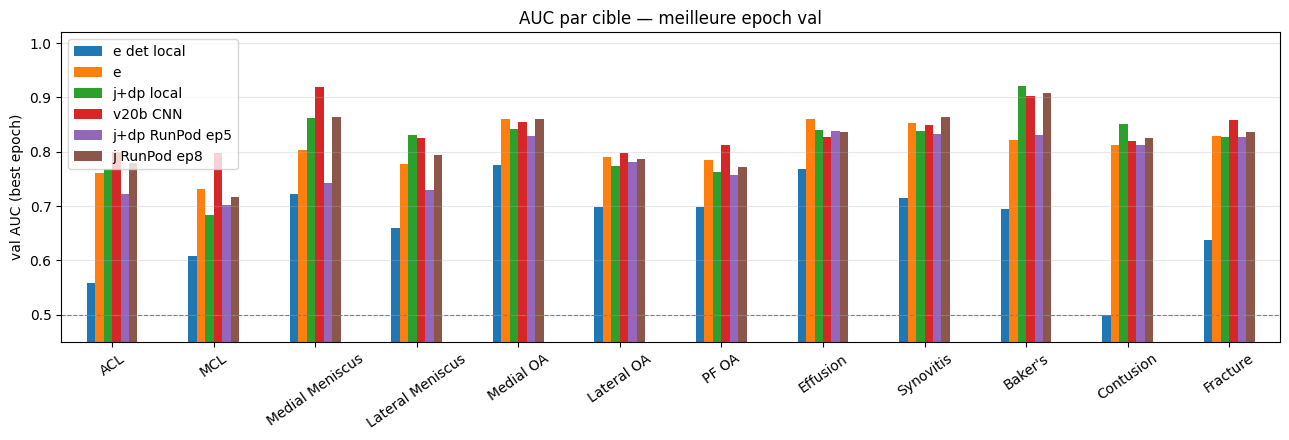

In [156]:
per = {}
for r in runs:
    row = r["hist"].loc[r["hist"]["val_macro_auc"].idxmax()]
    per[r["name"]] = {t: float(row[f"auc_{t}"]) for t in TARGETS if f"auc_{t}" in row.index}
per_df = pd.DataFrame(per).reindex(TARGETS)

if REF in per_df.columns:
    others = [c for c in per_df.columns if c != REF]
    for c in others:
        per_df[f"d_{c}"] = per_df[c] - per_df[REF]

display(per_df.round(3).style.apply(
    lambda s: ["font-weight: bold" if s.name in FOCUS else "" for _ in s],
    axis=1,
))

ax = per_df[[r["name"] for r in runs]].rename(
    columns={r["name"]: r["label"] for r in runs}
).plot(
    kind="bar", figsize=(13, 4.5), rot=35,
)
ax.set_ylabel("val AUC (best epoch)")
ax.set_ylim(0.45, 1.02)
ax.set_title("AUC par cible — meilleure epoch val")
ax.axhline(0.5, color="gray", lw=0.8, ls="--")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## Delta par cible vs v20b

Positif = le run bat le CNN de référence (v20b) sur cette cible. Le ViT devrait
surtout aider en spécialiste (ensemble), pas tout gagner en macro. Δ &lt; 0,01 = bruit.


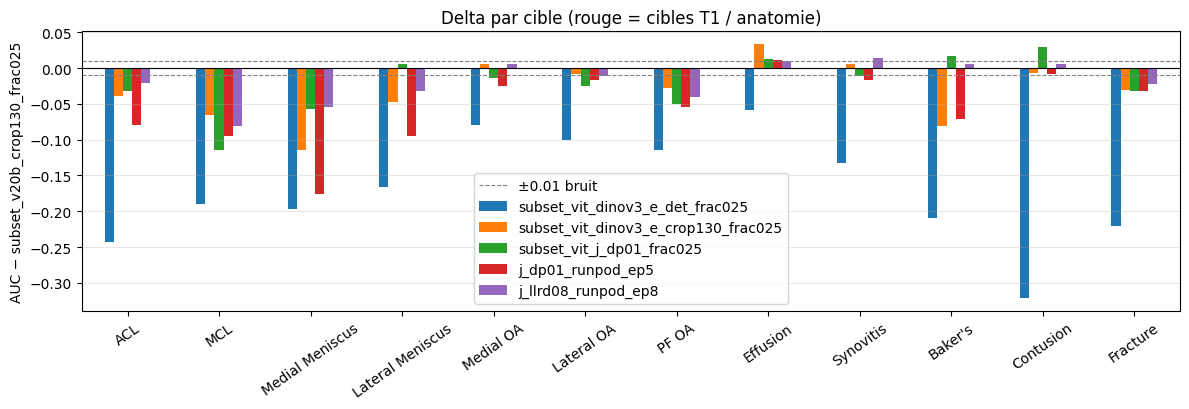

FOCUS (T1 attendu) :


,subset_vit_dinov3_e_det_frac025,subset_vit_dinov3_e_crop130_frac025,subset_vit_j_dp01_frac025,subset_v20b_crop130_frac025,j_dp01_runpod_ep5,j_llrd08_runpod_ep8,d_subset_vit_dinov3_e_det_frac025,d_subset_vit_dinov3_e_crop130_frac025,d_subset_vit_j_dp01_frac025,d_j_dp01_runpod_ep5,d_j_llrd08_runpod_ep8
Lateral OA,0.697,0.790,0.773,0.798,0.782,0.787,-0.101,-0.009,-0.025,-0.017,-0.011
MCL,0.608,0.732,0.683,0.797,0.703,0.716,-0.190,-0.065,-0.114,-0.095,-0.081
ACL,0.557,0.762,0.768,0.800,0.721,0.779,-0.243,-0.039,-0.032,-0.079,-0.021
Medial Meniscus,0.722,0.804,0.862,0.919,0.742,0.865,-0.197,-0.115,-0.057,-0.177,-0.054


In [157]:
delta_cols = [c for c in per_df.columns if c.startswith("d_")]
if not delta_cols:
    print(f"pas de delta : il faut au moins 2 runs, dont REF={REF!r} charge.")
else:
    fig, ax = plt.subplots(figsize=(12, 4.2))
    d = per_df[delta_cols].copy()
    d.columns = [c[2:] for c in d.columns]
    colors_focus = ["#c44e52" if t in FOCUS else "#4c72b0" for t in d.index]
    # un seul comparateur : barres simples ; plusieurs : grouped
    if d.shape[1] == 1:
        ax.bar(range(len(d)), d.iloc[:, 0], color=colors_focus, edgecolor="black", lw=0.3)
        ax.set_xticks(range(len(d)))
        ax.set_xticklabels(d.index, rotation=35, ha="right")
        ax.set_ylabel(f"AUC {d.columns[0]} − {REF}")
    else:
        d.plot(kind="bar", ax=ax, rot=35)
        ax.set_ylabel(f"AUC − {REF}")
    ax.axhline(0.0, color="black", lw=0.8)
    ax.axhline(0.01, color="gray", ls="--", lw=0.8, label="±0.01 bruit")
    ax.axhline(-0.01, color="gray", ls="--", lw=0.8)
    ax.set_title("Delta par cible (rouge = cibles T1 / anatomie)")
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    print("FOCUS (T1 attendu) :")
    display(per_df.loc[FOCUS].round(3))

## Courbes des cibles FOCUS (toutes les epochs)

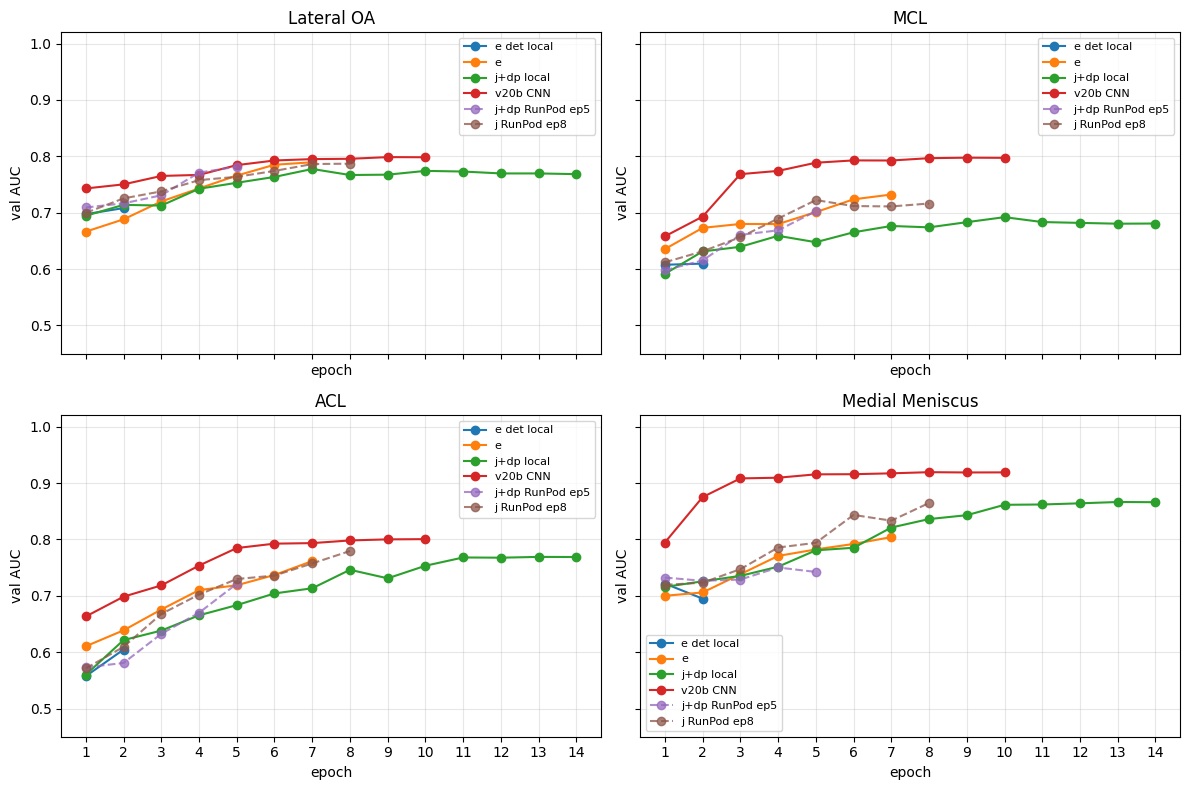

In [158]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True)
emax = max(int(r["hist"]["epoch"].max()) for r in runs)
for ax, tgt in zip(axes.ravel(), FOCUS):
    col = f"auc_{tgt}"
    for r in runs:
        h = r["hist"].sort_values("epoch")
        if col not in h.columns:
            continue
        ax.plot(h.epoch, h[col], **line_kw(r))
    ax.set_title(tgt)
    ax.set_ylim(0.45, 1.02)
    ax.set_xticks(range(1, emax + 1))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("val AUC")
plt.tight_layout()
plt.show()

## Même subset ? (train_uids)

Les YAML subset partagent `train_frac_seed: 42`. L'overlap doit être 100 %.

In [159]:
uid_sets = {r["name"]: set(r["uids"]) for r in runs if r["uids"]}
if len(uid_sets) < 2:
    print("pas assez de train_uids.txt pour comparer (normal si un run n'a pas demarre)")
else:
    names = list(uid_sets)
    ref_n = names[0]
    sref = uid_sets[ref_n]
    ok = True
    print(f"ref UIDs : {LABELS.get(ref_n, ref_n)} ({len(sref)})")
    for n in names[1:]:
        s = uid_sets[n]
        print(
            f"  {LABELS.get(n, n)}: {len(s)} | "
            f"inter {len(sref & s)} | seulement ref {len(sref - s)} | "
            f"seulement run {len(s - sref)}"
        )
        if s != sref:
            ok = False
    if ok:
        print("OK : exactement les memes etudes train")
    else:
        print("ATTENTION : subsets differents, la comparaison d'archi n'est plus propre")


ref UIDs : e det local (924)
  e: 924 | inter 924 | seulement ref 0 | seulement run 0
  j+dp local: 924 | inter 924 | seulement ref 0 | seulement run 0
  v20b CNN: 924 | inter 924 | seulement ref 0 | seulement run 0
OK : exactement les memes etudes train


## Sanity gold du `best.pt` (si le run est fini)

`gold_sanity.json` n'est écrit qu'à la **fin** du script. Pendant l'entraînement,
utilise la courbe `gold_macro_auc` ci-dessus (loggée chaque epoch).

e det local: pas encore de gold_sanity.json
e: pas encore de gold_sanity.json
j+dp local: macro-AUC gold 0.8216  (best epoch 11)
v20b CNN: pas encore de gold_sanity.json


,subset_vit_j_dp01_frac025
ACL,0.848
MCL,0.710
Medial Meniscus,0.858
Lateral Meniscus,0.822
Medial OA,0.941
Lateral OA,0.774
PF OA,0.726
Effusion,0.735
Synovitis,0.671
Baker's,0.980


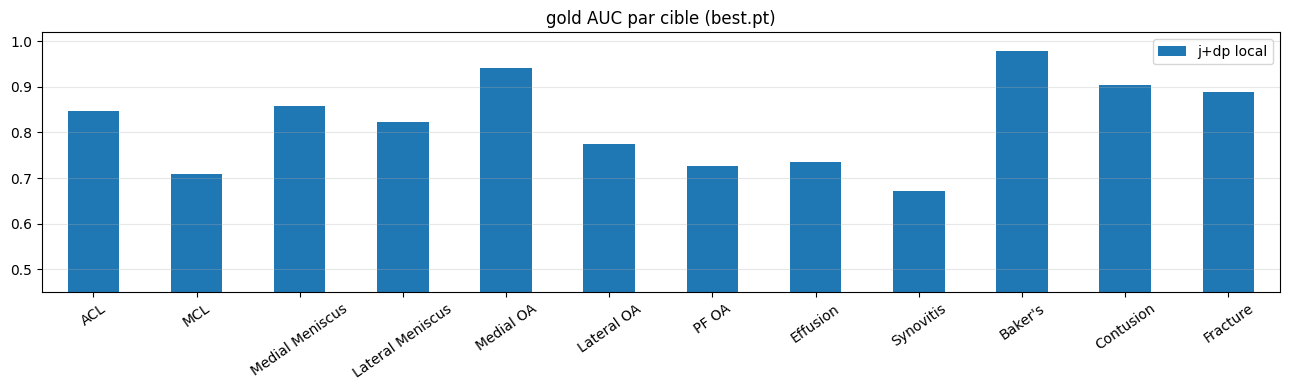

In [160]:
gcols = {}
for r in runs:
    if r.get("overlay"):
        continue
    if not r["gold"]:
        print(f"{r['label']}: pas encore de gold_sanity.json")
        continue
    g = r["gold"]
    print(f"{r['label']}: macro-AUC gold {g['macro_auc']:.4f}  (best epoch {g.get('epoch', '?')})")
    gcols[r["name"]] = pd.Series(g["per_target"])
if gcols:
    gdf = pd.DataFrame(gcols).reindex(TARGETS)
    if REF in gdf.columns:
        for c in gdf.columns:
            if c != REF:
                gdf[f"d_{c}"] = gdf[c] - gdf[REF]
    display(gdf.round(3))
    gdf[[r["name"] for r in runs if r["name"] in gdf.columns]].rename(
        columns={r["name"]: r["label"] for r in runs if r["name"] in gdf.columns}
    ).plot(
        kind="bar", figsize=(13, 4), rot=35, title="gold AUC par cible (best.pt)",
    )
    plt.ylim(0.45, 1.02)
    plt.grid(True, axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

## Comment lire

1. **Val macro-AUC** : critère principal. Δ &lt; 0,01 → on ne déclare pas de gagnant.
2. **Réf CNN** : v20b (val ~0,839 / gold ~0,885). Un ViT qui reste ~0,02 en dessous
   en macro peut quand même servir en **ensemble**.
3. **j vs k vs j+dp** : j = k + fusion blocs {6,9,12} ; j+dp = j + drop-path 0,1
   (off pendant le freeze). Juger le dp sur la **val_loss tardive** (k explosait
   0,41 → 0,61) et le gold après ep8, pas sur l'ep1 gelée.
4. **e det vs e** : même graphe / lr / data crop130. Seul le RNG local est figé.
   Un écart vs e original mesure le stack 3070+det, pas un levier d'archi.
5. **Gold** : n=58, très bruité. Un écart gold sans écart val n'est pas une preuve.
   Ne jamais piloter le checkpoint sur le gold.

Pour rafraîchir pendant que e det tourne : **re-exécuter à partir de la cellule Load**.
